# Belirsizlik Altinda Siber Olay Mudahalesi

Bu notebook; Bayes guncellemesi, belief state, beklenen fayda, Bilgi Degeri, MDP/POMDP, BDK-POMDP, 540 deney simulasyonu, Brier skoru ve Mudahale Guven Skoru hesaplarini tekrar uretmek icin hazirlanmistir.

**Deney ayarlari:** seed=42, tekrar=5, gamma=0.90, maksimum izinli adim=5.

> Not: Deney dokumaninda sayisal gecikme cezasi katsayisi verilmedigi icin tek-adimli EU hesabinda gecikme cezasi 0 alinmistir. Gecikme, sirali modeller ve OMG metrigi ile ayri olarak olculur.


In [ ]:
from pathlib import Path
import importlib.util, csv, json
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

BASE = Path("../csv")
print('Calisma dizini:', BASE)


Calisma dizini: /mnt/data/deney6_output


## 1. Ana deney kodunun calistirilmasi

In [2]:
spec = importlib.util.spec_from_file_location('deney6_solution', BASE/'deney6_solution.py')
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
print('Ana simulasyon tamamlandi.')


{
  "O1 posterior": {
    "S0": 0.3594771241830066,
    "S1": 0.5310457516339869,
    "S2": 0.09803921568627451,
    "S3": 0.011437908496732029
  },
  "MDP policy": {
    "S0": "A0",
    "S1": "A3",
    "S2": "A5",
    "S3": "A4",
    "S4": "A0"
  },
  "Best MGS": [
    "M4",
    80.77777777777777
  ],
  "Best deployable": [
    "M8",
    79.14538236398784
  ],
  "Highest YIO": [
    "M0",
    33.333333333333336
  ],
  "Highest OSO": [
    "M4",
    68.88888888888889
  ],
  "Positive VOI count": 2,
  "Metrics": {
    "M0": {
      "OSO": 42.22222222222222,
      "YIO": 33.333333333333336,
      "DKO": 66.66666666666667,
      "IYO": 0.0,
      "OMG": 2.4285714285714284,
      "BTO": 0.0,
      "YBTO": 0.0,
      "Brier": 0.10378880208333334,
      "Kalibrasyon": 89.62111979166667,
      "GecikmeBasarisi": 51.42857142857144,
      "MGS": 57.91935844494048,
      "Duzey": "Orta"
    },
    "M1": {
      "OSO": 48.888888888888886,
      "YIO": 0.0,
      "DKO": 83.33333333333333,
      "I

## 2. O1 gozlemi icin Bayes hesabi

In [3]:
bayes_o1 = pd.read_csv(BASE/'bayes_o1.csv')
bayes_o1


,Durum,Onsel,P(O1|S),Carpim,Sonsal
0,S0,0.55,0.20,0.1100,0.359477
1,S1,0.25,0.65,0.1625,0.531046
2,S2,0.15,0.20,0.0300,0.098039
3,S3,0.05,0.07,0.0035,0.011438
4,Toplam,NaN,NaN,0.3060,1.000000


## 3. Ardisik gozlemler sonrasi son belief state

In [4]:
belief = pd.read_csv(BASE/'belief_updates.csv')
final_belief = belief.groupby('Senaryo', as_index=False).tail(1)
final_belief[['Senaryo','P(S0)','P(S1)','P(S2)','P(S3)','En_Olasi_Durum']].reset_index(drop=True)


,Senaryo,P(S0),P(S1),P(S2),P(S3),En_Olasi_Durum
0,S1,0.967377,0.025842,0.006071,0.000709,S0
1,S2,0.200406,0.686213,0.101573,0.011808,S1
2,S3,0.138935,0.274460,0.528131,0.058474,S2
3,S4,0.025462,0.047409,0.239187,0.687942,S3
4,S5,0.774650,0.174890,0.044871,0.005589,S0
5,S6,0.592293,0.138447,0.243922,0.025339,S0
6,S7,0.663308,0.128980,0.112759,0.094953,S0
7,S8,0.014310,0.054530,0.242712,0.688448,S3
8,S9,0.062233,0.086905,0.730759,0.120102,S2
9,S10,0.079573,0.209589,0.241982,0.468856,S3


## 4. Beklenen fayda ve Bilgi Degeri

In [5]:
eu = pd.read_csv(BASE/'expected_utility.csv')
best_eu = eu.loc[eu.groupby('Senaryo')['Beklenen_Fayda'].idxmax(), ['Senaryo','Eylem','Beklenen_Fayda']]
best_eu.reset_index(drop=True)


,Senaryo,Eylem,Beklenen_Fayda
0,S1,A0,0.040297
1,S10,A5,23.649344
2,S11,A0,0.103218
3,S12,A5,37.262562
4,S2,A2,2.607005
5,S3,A5,14.869291
6,S4,A5,32.292082
7,S5,A0,0.278046
8,S6,A0,0.491104
9,S7,A0,0.391489


In [6]:
voi = pd.read_csv(BASE/'value_of_information.csv')
voi[voi['Bilgi_Degeri'] > 0][['Senaryo','Test','Bilgi_Degeri','Karar']].reset_index(drop=True)


,Senaryo,Test,Bilgi_Degeri,Karar
0,S6,T1,0.831676,Test yapilabilir
1,S6,T2,0.314569,Test yapilabilir


## 5. MDP politikasi

In [7]:
pd.read_csv(BASE/'mdp_policy.csv')


,Durum,Durum_Adi,Eylem,Eylem_Adi,Tek_Adim_EU,MDP_Q,Gerekce
0,S0,Normal,A0,Izlemeye devam et,0.0,-24.074470,"Tam gozlemlenebilir MDP value iteration, gamma..."
1,S1,Kimlik ele gecirme,A3,Supheli oturumu sonlandir ve hesabi sifirla,5.0,-59.149530,"Tam gozlemlenebilir MDP value iteration, gamma..."
2,S2,Yanal hareket,A5,Insan guvenlik uzmanina yonlendir,27.0,-116.193282,"Tam gozlemlenebilir MDP value iteration, gamma..."
3,S3,Veri sizdirma,A4,Uc cihazi izole et,35.0,-190.256078,"Tam gozlemlenebilir MDP value iteration, gamma..."
4,S4,Sinirlandirilmis,A0,Izlemeye devam et,0.0,-7.471387,"Tam gozlemlenebilir MDP value iteration, gamma..."


## 6. 540 deney ve genel metrikler

In [8]:
runs = pd.read_csv(BASE/'experiment_540_runs.csv')
print('Toplam deney satiri:', len(runs))
metrics = pd.read_csv(BASE/'general_metrics.csv')
metrics


Toplam deney satiri: 540


,Model,OSO,YIO,DKO,IYO,OMG,BTO,YBTO,Brier,Kalibrasyon_Basarisi,Gecikme_Basarisi,MGS,Duzey
0,M0,42.222222,33.333333,66.666667,0.000000,2.428571,0.000000,0.0,0.103789,89.621120,51.428571,57.919358,Orta
1,M1,48.888889,0.000000,83.333333,0.000000,2.428571,0.000000,0.0,0.153097,84.690272,51.428571,69.179731,Orta
2,M2,48.888889,0.000000,83.333333,0.000000,2.428571,0.000000,0.0,0.086888,91.311166,51.428571,70.172865,Guvenilir
3,M3,53.333333,0.000000,91.666667,0.000000,2.500000,8.333333,100.0,0.076310,92.368999,50.000000,78.188683,Guvenilir
4,M4,68.888889,0.000000,100.000000,0.000000,2.444444,0.000000,0.0,0.000000,100.000000,51.111111,80.777778,Guvenilir
5,M5,53.333333,0.000000,83.333333,41.666667,2.375000,0.000000,0.0,0.086888,91.311166,52.500000,71.613342,Guvenilir
6,M6,55.555556,0.000000,88.333333,46.666667,2.473684,8.333333,100.0,0.085502,91.449774,50.526316,78.103431,Guvenilir
7,M7,53.333333,33.333333,66.666667,0.000000,2.300000,0.000000,0.0,0.088580,91.141959,54.000000,61.737961,Orta
8,M8,57.777778,0.000000,90.000000,48.333333,2.487179,8.333333,100.0,0.080906,91.909387,50.256410,79.145382,Guvenilir


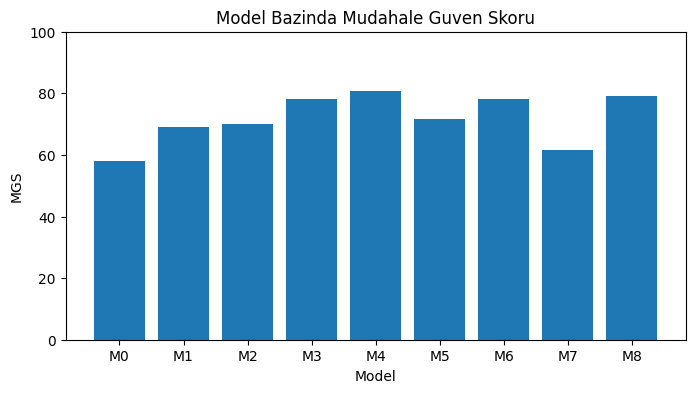

In [9]:
plt.figure(figsize=(8,4))
plt.bar(metrics['Model'], metrics['MGS'])
plt.ylim(0,100)
plt.xlabel('Model')
plt.ylabel('MGS')
plt.title('Model Bazinda Mudahale Guven Skoru')
plt.show()


## 7. Ablation analizi

In [10]:
ablation = pd.read_csv(BASE/'ablation_results.csv')
ablation


,Yapilandirma,Aciklama,OSO,YIO,DKO,Test_Maliyeti,OMG,MGS
0,AB0,Yalnizca sabit alarm esigi,46.666667,33.333333,66.666667,0,2.428571,59.252692
1,AB1,"Bayes guncellemesi var, Bilgi Degeri yok",40.000000,0.000000,83.333333,0,2.428571,67.506199
2,AB2,"POMDP var, test maliyeti yok",64.444444,0.000000,90.000000,430,3.121951,75.038991
3,AB3,POMDP + test maliyeti,64.444444,0.000000,90.000000,45,2.634146,75.953420
4,AB4,POMDP + Bilgi Degeri,57.777778,0.000000,86.666667,15,2.459459,73.396272
5,AB5,POMDP + Bilgi Degeri + insan yonlendirme kapisi,62.222222,0.000000,90.000000,15,2.487179,75.478716


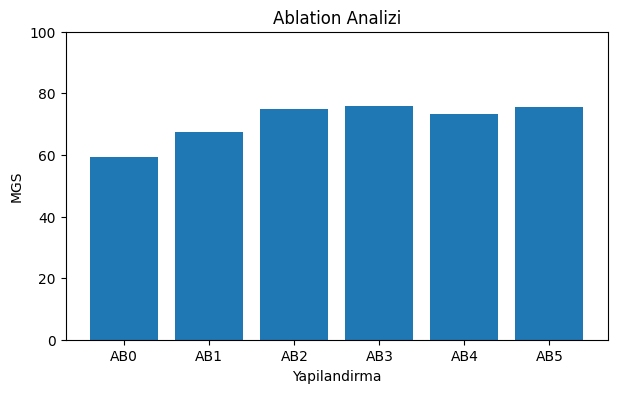

In [11]:
plt.figure(figsize=(7,4))
plt.bar(ablation['Yapilandirma'], ablation['MGS'])
plt.ylim(0,100)
plt.xlabel('Yapilandirma')
plt.ylabel('MGS')
plt.title('Ablation Analizi')
plt.show()


## 8. Sonuc

- O1 tek gozlemi sonrasinda en yuksek sonsal olasilik S1 icin elde edilir.
- Sabit esik ve ham LLM yaklasimlari normal senaryolarda yanlis izolasyon uretebilir.
- M4, gercek durumu bildigi varsayilan oracle MDP oldugu icin teorik ust sinir niteligindedir.
- Gercek durumu bilmeyen uygulanabilir modeller icinde M8 (LLM + BDK-POMDP kontrolu) en yuksek MGS degerini elde etmistir.
- Bilgi Degeri kapisi, S6 gibi belirsiz durumlarda ek testin net karar katkisini olcerek gereksiz testleri engeller.
